In [ ]:
import numpy as np
import pandas as pd
import os

In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

base_path = (
    "/content/drive/MyDrive/"
    "Gender classification from tongue images-20261019T043949Z-1-001/"
    "Gender classification from tongue images"
)

print("Path exists:", os.path.isdir(base_path))
print("Folders:", os.listdir(base_path) if os.path.isdir(base_path) else "Path not found")


Path exists: True
Folders: ['Male 311', 'Female 390']


In [ ]:

import pandas as pd

data = []
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

class_folders = {
    "female": os.path.join(base_path, "Female 390"),
    "male": os.path.join(base_path, "Male 311")
}

for label, folder_path in class_folders.items():
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(
            f"Class folder not found: {folder_path}"
        )

    for root, dirs, files in os.walk(folder_path):
        for filename in files:
            if filename.lower().endswith(extensions):
                image_path = os.path.join(root, filename)
                data.append([image_path, label])

df = pd.DataFrame(data, columns=["image_path", "label"])

print("Total images:", len(df))
print(df["label"].value_counts())


Total images: 655
label
female    352
male      303
Name: count, dtype: int64


In [ ]:
df

,image_path,label
0,/content/drive/MyDrive/Gender classification f...,female
1,/content/drive/MyDrive/Gender classification f...,female
2,/content/drive/MyDrive/Gender classification f...,female
3,/content/drive/MyDrive/Gender classification f...,female
4,/content/drive/MyDrive/Gender classification f...,female
...,...,...
650,/content/drive/MyDrive/Gender classification f...,male
651,/content/drive/MyDrive/Gender classification f...,male
652,/content/drive/MyDrive/Gender classification f...,male
653,/content/drive/MyDrive/Gender classification f...,male


In [ ]:
df.shape

(655, 2)

In [ ]:
df.columns

Index(['image_path', 'label'], dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
image_path,0
label,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 655 entries, 0 to 654
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  655 non-null    object
 1   label       655 non-null    object
dtypes: object(2)
memory usage: 10.4+ KB


In [ ]:
df['label'].unique()

array(['female', 'male'], dtype=object)

In [ ]:
df['label'].value_counts()

,count
label,
female,352
male,303


/tmp/ipykernel_2632/22806488.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", palette="viridis", ax=ax)


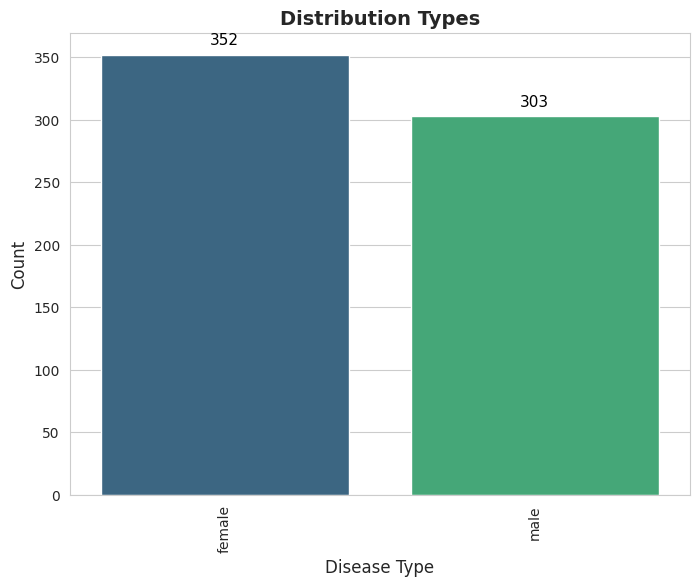

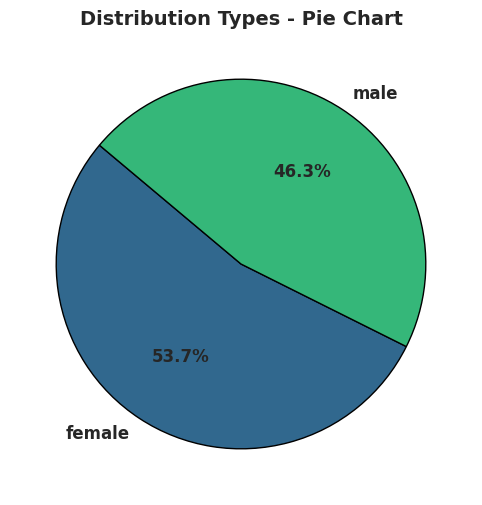

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(data=df, x="label", palette="viridis", ax=ax)

ax.set_title("Distribution Types", fontsize=14, fontweight='bold')
ax.set_xlabel("Disease Type", fontsize=12)
ax.set_ylabel("Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, color='black',
                xytext=(0, 5), textcoords='offset points')

plt.xticks(rotation = 90)
plt.show()

label_counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("viridis", len(label_counts))

ax.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%',
       startangle=140, colors=colors, textprops={'fontsize': 12, 'weight': 'bold'},
       wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax.set_title("Distribution Types - Pie Chart", fontsize=14, fontweight='bold')

plt.show()

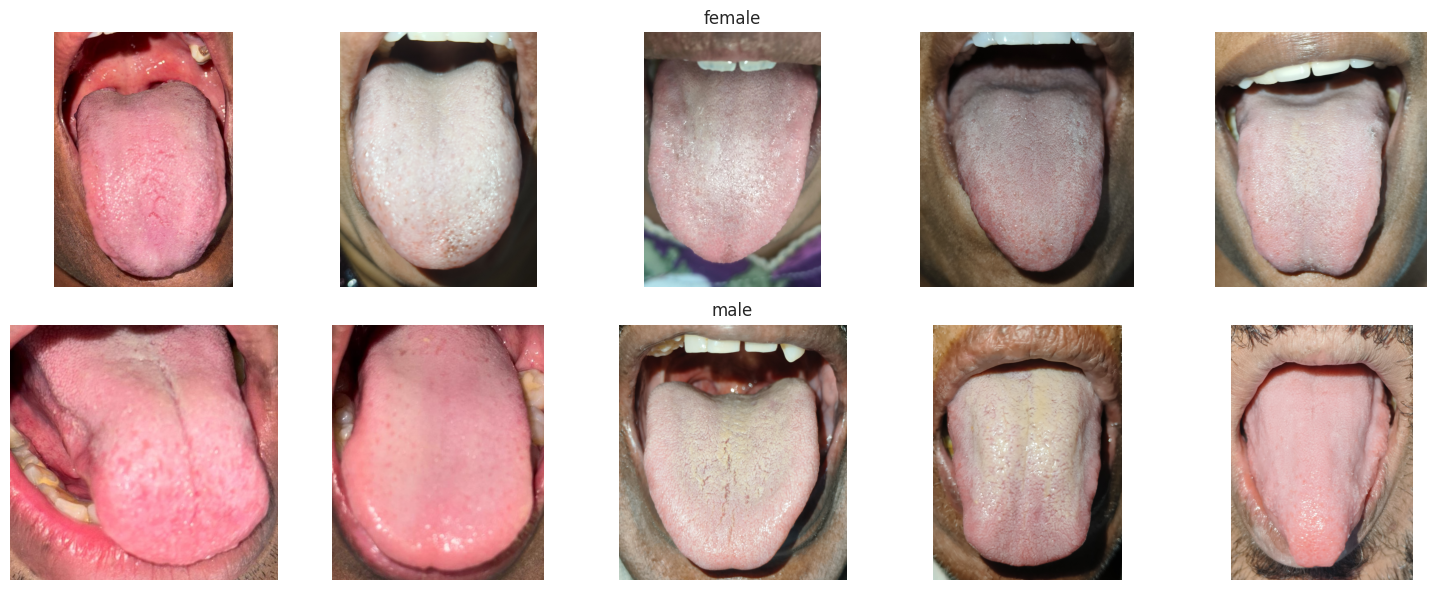

In [ ]:
import cv2

label_groups = {label: group.head(5)['image_path'].tolist()
                for label, group in df.groupby('label')}

num_labels = len(label_groups)

plt.figure(figsize=(15, 3 * num_labels))

for row, (label, images) in enumerate(label_groups.items()):
    for col, img_path in enumerate(images):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(num_labels, 5, row * 5 + col + 1)
        plt.imshow(img)
        plt.axis('off')
        if col == 2:
            plt.title(label, fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
CLASS_NAMES = ["female", "male"]

num_classes = len(CLASS_NAMES)

name2id = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

id2name = {
    idx: name
    for idx, name in enumerate(CLASS_NAMES)
}

In [ ]:
from sklearn.utils import resample

max_count = df['label'].value_counts().max()

dfs = []
for category in df['label'].unique():
    class_subset = df[df['label'] == category]
    class_upsampled = resample(class_subset,
                               replace=True,
                               n_samples=max_count,
                               random_state=42)
    dfs.append(class_upsampled)

df_balanced = pd.concat(dfs).sample(frac=1, random_state=42).reset_index(drop=True)

In [ ]:
df = df_balanced

In [ ]:
df

,image_path,label
0,/content/drive/MyDrive/Gender classification f...,female
1,/content/drive/MyDrive/Gender classification f...,female
2,/content/drive/MyDrive/Gender classification f...,female
3,/content/drive/MyDrive/Gender classification f...,female
4,/content/drive/MyDrive/Gender classification f...,female
...,...,...
699,/content/drive/MyDrive/Gender classification f...,female
700,/content/drive/MyDrive/Gender classification f...,female
701,/content/drive/MyDrive/Gender classification f...,female
702,/content/drive/MyDrive/Gender classification f...,male


In [ ]:
df['label'].value_counts()

,count
label,
female,352
male,352


In [ ]:
CLASS_NAMES = ["female", "male"]

num_classes = len(CLASS_NAMES)

name2id = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

id2name = {
    idx: name
    for idx, name in enumerate(CLASS_NAMES)
}

In [ ]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Truncated image loading enabled.")

Truncated image loading enabled.


In [ ]:
from PIL import Image
import os

bad_images = []

for path in df["image_path"]:
    try:
        with Image.open(path) as img:
            img.verify()

        # Reopen and force the image data to load
        with Image.open(path) as img:
            img.convert("RGB").load()

    except Exception as e:
        bad_images.append((path, str(e)))

print("Total images checked:", len(df))
print("Damaged images found:", len(bad_images))

for path, error in bad_images:
    print(path, "->", error)

Total images checked: 704
Damaged images found: 0


In [ ]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Image loading setting updated.")

Image loading setting updated.


In [ ]:
print([name for name in globals()
       if "train" in name.lower()
       or "val" in name.lower()
       or "test" in name.lower()
       or "dataset" in name.lower()])

[]


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

search_root = "/content/drive/MyDrive"
matches = []

for root, dirs, files in os.walk(search_root):
    # Skip common folders that can contain many unrelated files
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", "node_modules"}
    ]

    for filename in files:
        if filename.lower() in {
            "vgg19_gender_best.pt",
            "vgg19_gender_best.pth"
        }:
            matches.append(os.path.join(root, filename))

print("Checkpoints found:", len(matches))

for path in matches:
    print(path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints found: 0


In [ ]:
from torch.utils.data import DataLoader
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

train_loader = DataLoader(
    train_ds,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_ds,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_ds,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("All DataLoaders recreated successfully!")

NameError: name 'train_ds' is not defined

In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image loading successful!")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image loading successful!


Dataset images: 704

Class distribution:
label
female    352
male      352
Name: count, dtype: int64

Dataset split:
Train: 492
Validation: 106
Test: 106

Using device: cuda

VGG19 loaded successfully.
Output classes: ['female', 'male']
Epoch 01/20 | Train Loss: 0.6189 | Train Acc: 0.6565 | Val Loss: 0.3946 | Val Acc: 0.8491
Saved best model: /content/vgg19_gender_best.pt
Epoch 02/20 | Train Loss: 0.4098 | Train Acc: 0.8150 | Val Loss: 0.3192 | Val Acc: 0.8679
Saved best model: /content/vgg19_gender_best.pt
Epoch 03/20 | Train Loss: 0.3171 | Train Acc: 0.8618 | Val Loss: 0.3031 | Val Acc: 0.8774
Saved best model: /content/vgg19_gender_best.pt
Epoch 04/20 | Train Loss: 0.2920 | Train Acc: 0.8862 | Val Loss: 0.3613 | Val Acc: 0.8679
Epoch 05/20 | Train Loss: 0.2288 | Train Acc: 0.9085 | Val Loss: 0.6741 | Val Acc: 0.7830
Epoch 06/20 | Train Loss: 0.2048 | Train Acc: 0.9167 | Val Loss: 0.2445 | Val Acc: 0.9151
Saved best model: /content/vgg19_gender_best.pt
Epoch 07/20 | Train Loss: 0.206

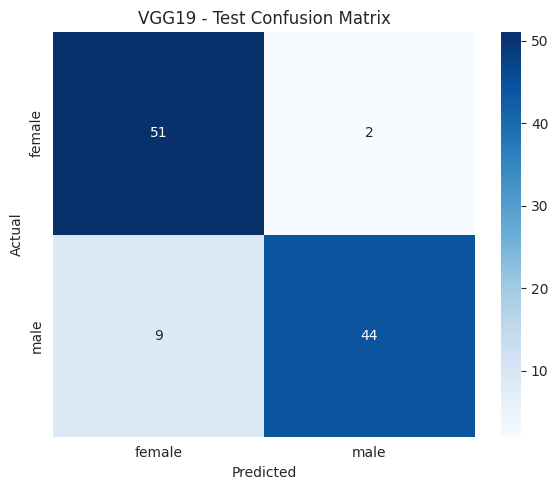

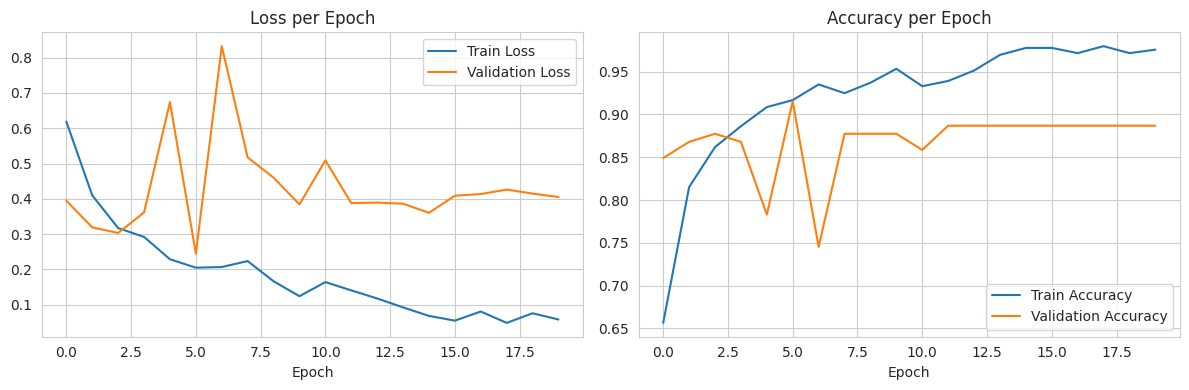


Classification report saved.
Checkpoint: /content/vgg19_gender_best.pt

========== VGG19 PARAMETERS ==========
Total parameters: 139,578,434
Trainable parameters: 119,554,050
Frozen parameters: 20,024,384


In [ ]:

# ==========================================
# VGG19 Gender Classification - Complete Code
# ==========================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


# ==========================================
# 1. Classes
# ==========================================

CLASS_NAMES = ["female", "male"]
num_classes = len(CLASS_NAMES)

name2id = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# Check dataset columns and labels
required_columns = {"image_path", "label"}

if not required_columns.issubset(df.columns):
    raise ValueError("df must contain image_path and label columns.")

df = df.copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()

print("Dataset images:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())

unknown_labels = set(df["label"].unique()) - set(CLASS_NAMES)

if unknown_labels:
    raise ValueError(f"Unexpected labels found: {unknown_labels}")

df["label_id"] = df["label"].map(name2id).astype(int)


# ==========================================
# 2. Check image paths
# ==========================================

missing = ~df["image_path"].apply(os.path.isfile)

if missing.any():
    print("Missing image files:", int(missing.sum()))
    raise FileNotFoundError(
        "Some image paths do not exist. Check your dataset path."
    )


# ==========================================
# 3. Train / Validation / Test split
# ==========================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("\nDataset split:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# ==========================================
# 4. Dataset class
# ==========================================

class ImageDFDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            img = img.convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = int(row["label_id"])

        return img, label


# ==========================================
# 5. Image preprocessing
# ==========================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_ds = ImageDFDataset(train_df, train_tfms)
val_ds = ImageDFDataset(val_df, eval_tfms)
test_ds = ImageDFDataset(test_df, eval_tfms)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nUsing device:", device)

# Use fewer workers for reliable Colab execution
train_loader = DataLoader(
    train_ds, batch_size=16, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds, batch_size=16, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_ds, batch_size=16, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)


# ==========================================
# 6. Load pretrained VGG19
# ==========================================

try:
    model = models.vgg19(
        weights=models.VGG19_Weights.DEFAULT
    )
except Exception as e:
    raise RuntimeError(
        "Could not load pretrained VGG19 weights. "
        "Check your internet connection and torchvision installation."
    ) from e

# Freeze convolutional feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Replace final layer with two output classes
in_features = model.classifier[-1].in_features

model.classifier[-1] = nn.Linear(
    in_features, num_classes
)

model = model.to(device)

print("\nVGG19 loaded successfully.")
print("Output classes:", CLASS_NAMES)


# ==========================================
# 7. Loss, optimizer and scheduler
# ==========================================

criterion = nn.CrossEntropyLoss()

# Train only the classifier because features are frozen
optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ==========================================
# 8. Training and evaluation function
# ==========================================

def run_epoch(model, loader, training=False):

    model.train() if training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total = 0

    all_preds = []
    all_labels = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=5.0
                )
                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        total_correct += (
            predictions == labels
        ).sum().item()

        total += batch_size

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return (
        total_loss / total,
        total_correct / total,
        np.array(all_preds),
        np.array(all_labels)
    )


# ==========================================
# 9. Train model and save best checkpoint
# ==========================================

epochs = 20
best_val_loss = float("inf")
best_path = "/content/vgg19_gender_best.pt"

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(1, epochs + 1):

    train_loss, train_acc, _, _ = run_epoch(
        model, train_loader, training=True
    )

    val_loss, val_acc, _, _ = run_epoch(
        model, val_loader, training=False
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save({
            "model_state": model.state_dict(),
            "class_names": CLASS_NAMES,
            "best_val_loss": best_val_loss
        }, best_path)

        print("Saved best model:", best_path)


# ==========================================
# 10. Load best model
# ==========================================

checkpoint = torch.load(
    best_path, map_location=device, weights_only=False
)

model.load_state_dict(checkpoint["model_state"])
model.eval()

print("\nBest validation loss:", checkpoint["best_val_loss"])


# ==========================================
# 11. Evaluate on untouched test set
# ==========================================

test_loss, test_acc, y_pred, y_true = run_epoch(
    model, test_loader, training=False
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\nClassification Report:")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))


# ==========================================
# 12. Confusion matrix
# ==========================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("VGG19 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/vgg19_confusion_matrix.png", dpi=200)
plt.show()


# ==========================================
# 13. Training curves
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train Accuracy")
axes[1].plot(history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Accuracy per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/vgg19_training_curves.png", dpi=200)
plt.show()


# ==========================================
# 14. Save classification report
# ==========================================

report_dict = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    "/content/vgg19_classification_report.csv"
)

print("\nClassification report saved.")
print("Checkpoint:", best_path)


# ==========================================
# 15. Model parameter count
# ==========================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\n========== VGG19 PARAMETERS ==========")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{total_params - trainable_params:,}")
